# Перевірка адекватності моделі (етап 4)

Перевіряємо дискретну модель (особистий PageRank, PPR) і неперервну (теплове ядро) за пунктом «Перевірка адекватності» ТЗ:

1. збереження сумарної релевантності (= 1) і невід'ємність на кожному кроці;
2. збіжність без перезапуску до d/Σd (недводольний граф або ліниве блукання);
3. порівняння з аналітичними розв'язками на ланцюжку, циклі, зірці, повному графі;
4. збіг способів розрахунку всередині кожної моделі;
5. спадання похибки ітерацій ‖π_k − π*‖₁ не повільніше ніж (1 − α)^k;
6. граничні випадки параметрів.

Формули (1)–(19) — з `docs/analitychni_rozvyazky.md`. Усі обчислення моделей — лише через `reldiff.api.rank`.

In [1]:
import time
from pathlib import Path

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.linalg as sla

from reldiff.api import rank
from reldiff import analytic as A

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
RES = Path("../results"); RES.mkdir(exist_ok=True)
EPS = np.finfo(float).eps
print(f"Машинний епсилон: {EPS:.2e}")

def stationary(g):
    # d/Σd із зважених степенів, які повертає rank
    d = rank(g, next(iter(g)), "ppr", return_info=True)[1]["degrees"].to_numpy()
    return d / d.sum()

def connected_er(n, p, seed):
    # зв'язний граф Ердеша–Реньї: перебираємо seed, доки граф не стане зв'язним
    while True:
        g = nx.gnp_random_graph(n, p, seed=seed)
        if nx.is_connected(g):
            return g
        seed += 1000

# Тестові графи (явні seed)
g_er = connected_er(300, 0.02, seed=1)

g_ws = nx.connected_watts_strogatz_graph(300, 6, 0.1, seed=2)
rng = np.random.default_rng(2)
for u, v in g_ws.edges():
    g_ws[u][v]["weight"] = rng.uniform(0.1, 5.0)

g_dir = nx.gnp_random_graph(300, 0.015, seed=3, directed=True)
g_dir.remove_edges_from([e for v in range(10, 300, 20) for e in list(g_dir.out_edges(v))])  # 15 висячих вузлів
rng = np.random.default_rng(3)
for u, v in g_dir.edges():
    g_dir[u][v]["weight"] = rng.uniform(0.5, 2.0)
n_dangling = sum(1 for v in g_dir if g_dir.out_degree(v) == 0)

GRAPHS = {"ER (n=300)": g_er, "WS зважений (n=300)": g_ws, "орієнтований (n=300)": g_dir}
print(f"ER: {g_er.number_of_edges()} ребер, недводольний: {not nx.is_bipartite(g_er)}")
print(f"WS: {g_ws.number_of_edges()} ребер")
print(f"Орієнтований: {g_dir.number_of_edges()} дуг, висячих вузлів: {n_dangling}")

Машинний епсилон: 2.22e-16
ER: 951 ребер, недводольний: True
WS: 900 ребер
Орієнтований: 1355 дуг, висячих вузлів: 16


## Завдання 1. Збереження суми і невід'ємність

Для кожного кроку ітерацій PPR (α = 0.15) і блукання без перезапуску рахуємо відхилення суми від 1 і мінімальну компоненту. Для теплового ядра те саме перевіряємо на сітці t трьома способами. На орієнтованому графі перевіряємо обидві стратегії для висячих вузлів.

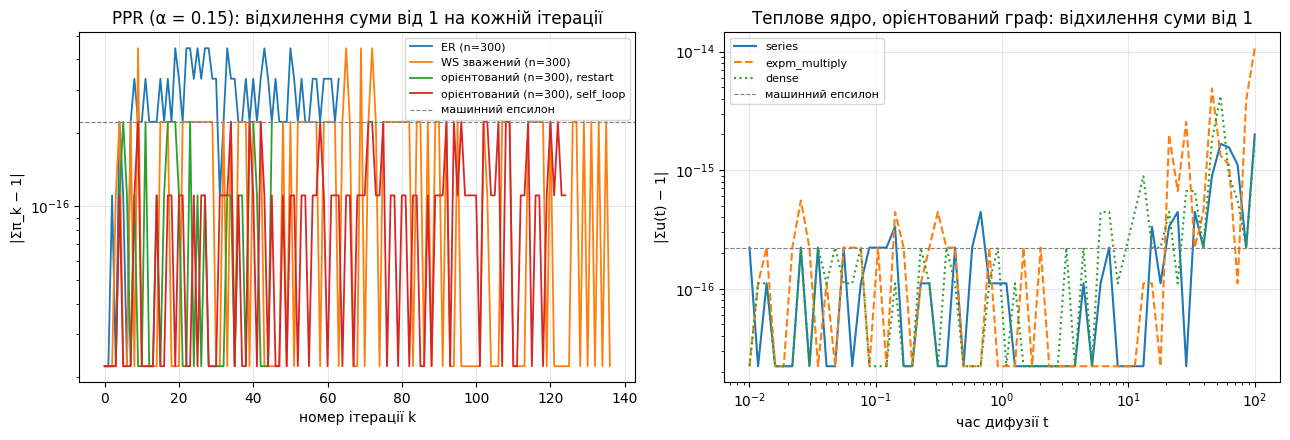

,граф,модель,кроків,макс_відхилення_суми,мін_компонента
0,ER (n=300),PPR ітерація,63,4.44e-16,0.00e+00
1,ER (n=300),блукання,300,2.89e-15,0.00e+00
2,WS зважений (n=300),PPR ітерація,136,4.44e-16,0.00e+00
3,WS зважений (n=300),блукання,300,4.44e-15,0.00e+00
4,"орієнтований (n=300), restart",PPR ітерація,45,2.22e-16,0.00e+00
5,"орієнтований (n=300), self_loop",PPR ітерація,124,2.22e-16,0.00e+00
6,орієнтований (n=300),блукання,300,4.44e-16,0.00e+00
7,ER (n=300),"теплове ядро, series",61,3.77e-15,0.00e+00
8,WS зважений (n=300),"теплове ядро, series",61,3.33e-15,0.00e+00
9,орієнтований (n=300),"теплове ядро, series",61,2.00e-15,0.00e+00


Найбільше відхилення суми: 1.77e-14
Найменша компонента: 0.00e+00


In [2]:
rows = []
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, g in GRAPHS.items():
    for dangling in ("restart", "self_loop"):
        if dangling == "self_loop" and not g.is_directed():
            continue                      # на неорієнтованих графах висячих вузлів немає
        _, info = rank(g, 0, "ppr", alpha=0.15, solver="iterative", dangling=dangling,
                       keep_trajectory=True, return_info=True)
        tr = info["trajectory"]
        dev = np.abs(tr.sum(axis=1) - 1)
        lab = name + ("" if not g.is_directed() else f", {dangling}")
        a1.semilogy(np.maximum(dev, EPS / 10), lw=1.3, label=lab)
        rows.append(dict(граф=lab, модель="PPR ітерація", кроків=len(tr) - 1,
                         макс_відхилення_суми=dev.max(), мін_компонента=tr.min()))

    _, info = rank(g, 0, "walk", steps=300, keep_trajectory=True, return_info=True)
    tr = info["trajectory"]
    rows.append(dict(граф=name, модель="блукання", кроків=300,
                     макс_відхилення_суми=np.abs(tr.sum(axis=1) - 1).max(), мін_компонента=tr.min()))

ts = np.r_[0, np.logspace(-2, 2, 60)]
for solver, ls in (("series", "-"), ("expm_multiply", "--"), ("dense", ":")):
    dev = [abs(rank(g_dir, 0, "heat", t=t, solver=solver).sum() - 1) for t in ts]
    a2.loglog(ts[1:], np.maximum(dev[1:], EPS / 10), ls, lw=1.5, label=solver)
    for name, g in GRAPHS.items():
        U = np.array([rank(g, 0, "heat", t=t, solver=solver).to_numpy() for t in ts])
        rows.append(dict(граф=name, модель=f"теплове ядро, {solver}", кроків=len(ts),
                         макс_відхилення_суми=np.abs(U.sum(axis=1) - 1).max(), мін_компонента=U.min()))

for ax in (a1, a2):
    ax.axhline(EPS, color="gray", ls="--", lw=0.8, label="машинний епсилон")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
a1.set_title("PPR (α = 0.15): відхилення суми від 1 на кожній ітерації")
a1.set_xlabel("номер ітерації k"); a1.set_ylabel("|Σπ_k − 1|")
a2.set_title("Теплове ядро, орієнтований граф: відхилення суми від 1")
a2.set_xlabel("час дифузії t"); a2.set_ylabel("|Σu(t) − 1|")
plt.tight_layout(); plt.savefig(FIG / "00_zberezhennya_sumy.png", dpi=200); plt.show()

tab_mass = pd.DataFrame(rows)
tab_mass.to_csv(RES / "00_zberezhennya_sumy.csv", index=False)
pd.set_option("display.float_format", "{:.2e}".format)
display(tab_mass)
print(f"Найбільше відхилення суми: {tab_mass['макс_відхилення_суми'].max():.2e}")
print(f"Найменша компонента: {tab_mass['мін_компонента'].min():.2e}")

## Завдання 2. Збіжність без перезапуску до d/Σd

Блукання π_{k+1} = π_k·P на зв'язному неорієнтованому графі має збігатися до π_i = d_i/Σd, якщо граф недводольний. На дводольному графі (парний цикл, зірка, ланцюжок) воно коливається, і тоді використовуємо ліниве блукання P' = (I + P)/2. Теплове ядро збігається на будь-якому зв'язному графі.

Швидкість збіжності визначає друге за модулем власне значення: ‖π_k − d/Σd‖₁ ~ |λ₂|^k. Для лінивого блукання це (1 + λ₂)/2, де λ₂ — друге за величиною власне значення P (найменше λ_min = −1 після перетворення дає 0). Для теплового ядра швидкість ~ e^(−t(1 − λ₂)). Це справедливо, якщо s має ненульову компоненту вздовж власного вектора λ₂. Наприклад, на зірці з запитом у центрі такої компоненти немає (розділ 4 виведення), і спадання швидше — e^(−2t). Тому для зірки беремо запит у листку.

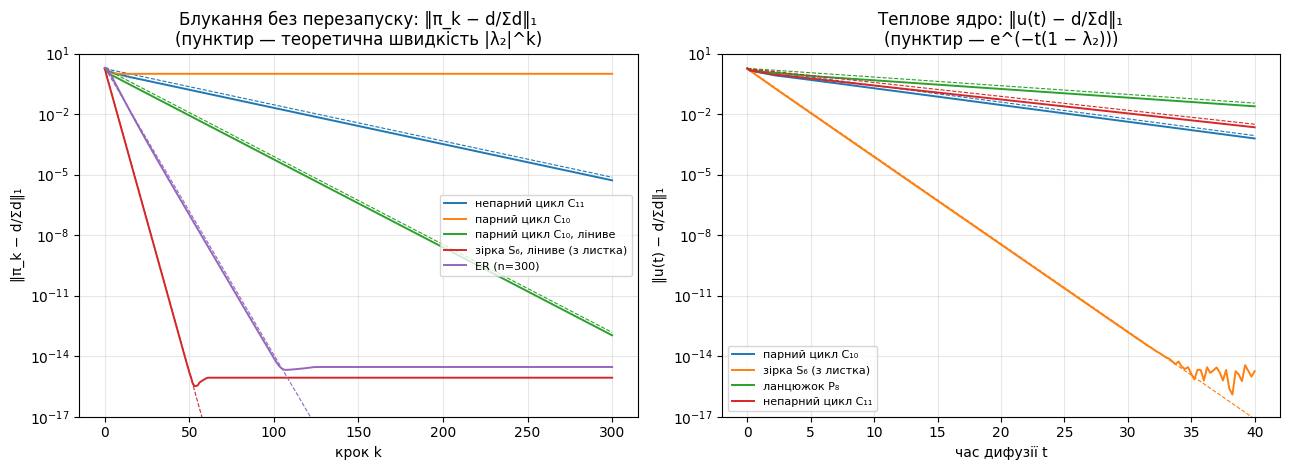

,граф,дводольний,ліниве,модуль_λ2,похибка_після_300_кроків
0,непарний цикл C₁₁,False,False,9.59e-01,5.24e-06
1,парний цикл C₁₀,True,False,1.00e+00,1.00e+00
2,"парний цикл C₁₀, ліниве",True,True,9.05e-01,1.09e-13
3,"зірка S₆, ліниве (з листка)",True,True,5.00e-01,8.60e-16
4,ER (n=300),False,False,7.21e-01,2.92e-15


In [3]:
def second_eig(g, lazy=False):
    # друге за модулем власне значення матриці переходів (щільно, малі графи)
    Wd = nx.to_numpy_array(g)
    P = Wd / Wd.sum(axis=1, keepdims=True)
    if lazy:
        P = (np.eye(len(P)) + P) / 2
    lam = np.sort(np.abs(np.linalg.eigvals(P)))[::-1]
    return lam[1]

def gap(g):
    # спектральна щілина 1 − λ₂ (λ₂ — друге за величиною, не за модулем)
    Wd = nx.to_numpy_array(g)
    P = Wd / Wd.sum(axis=1, keepdims=True)
    lam = np.sort(np.linalg.eigvals(P).real)[::-1]
    return 1 - lam[1]

cases = [("непарний цикл C₁₁", nx.cycle_graph(11), False),
         ("парний цикл C₁₀", nx.cycle_graph(10), False),
         ("парний цикл C₁₀, ліниве", nx.cycle_graph(10), True),
         ("зірка S₆, ліниве (з листка)", nx.star_graph(6), True),
         ("ER (n=300)", g_er, False)]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
K = 300
rows = []
for i, (name, g, lazy) in enumerate(cases):
    q = 1 if "зірка" in name else 0
    tr = rank(g, q, "walk", steps=K, lazy=lazy, keep_trajectory=True, return_info=True)[1]["trajectory"]
    err = np.abs(tr - stationary(g)).sum(axis=1)
    line, = a1.semilogy(np.maximum(err, 1e-17), lw=1.4, label=name)
    lam = second_eig(g, lazy)
    if lam < 1 - 1e-9:
        k = np.arange(K + 1)
        a1.semilogy(k, err[0] * lam ** k, "--", lw=0.8, color=line.get_color())
    rows.append(dict(граф=name, дводольний=nx.is_bipartite(g), ліниве=lazy,
                     модуль_λ2=lam, похибка_після_300_кроків=err[-1]))

a1.set_ylim(1e-17, 10)
a1.set_title("Блукання без перезапуску: ‖π_k − d/Σd‖₁\n(пунктир — теоретична швидкість |λ₂|^k)")
a1.set_xlabel("крок k"); a1.set_ylabel("‖π_k − d/Σd‖₁")
a1.grid(alpha=0.3); a1.legend(fontsize=8)

ts = np.linspace(0, 40, 161)
for name, g, q in [("парний цикл C₁₀", nx.cycle_graph(10), 0), ("зірка S₆ (з листка)", nx.star_graph(6), 1),
                   ("ланцюжок P₈", nx.path_graph(8), 0), ("непарний цикл C₁₁", nx.cycle_graph(11), 0)]:
    pi_inf = stationary(g)
    err = [np.abs(rank(g, q, "heat", t=t).to_numpy() - pi_inf).sum() for t in ts]
    line, = a2.semilogy(ts, np.maximum(err, 1e-17), lw=1.4, label=name)
    a2.semilogy(ts, err[0] * np.exp(-gap(g) * ts), "--", lw=0.8, color=line.get_color())
a2.set_ylim(1e-17, 10)
a2.set_title("Теплове ядро: ‖u(t) − d/Σd‖₁\n(пунктир — e^(−t(1 − λ₂)))")
a2.set_xlabel("час дифузії t"); a2.set_ylabel("‖u(t) − d/Σd‖₁")
a2.grid(alpha=0.3); a2.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "00_zbizhnist_bez_perezapusku.png", dpi=200); plt.show()

tab_stat = pd.DataFrame(rows)
tab_stat.to_csv(RES / "00_zbizhnist_bez_perezapusku.csv", index=False)
display(tab_stat)

**Контраст: комбінаторний лапласіан.** Дифузія du/dt = −u·(D − W) теж зберігає суму, бо (D − W)·**1** = 0. Але вона збігається до **рівномірного** розподілу, а не до d/Σd. Покажемо це на зірці S₆, де степені дуже різні. Тут обчислюємо щільну експоненту прямо, бо це не модель курсової, а лише порівняння для звіту.

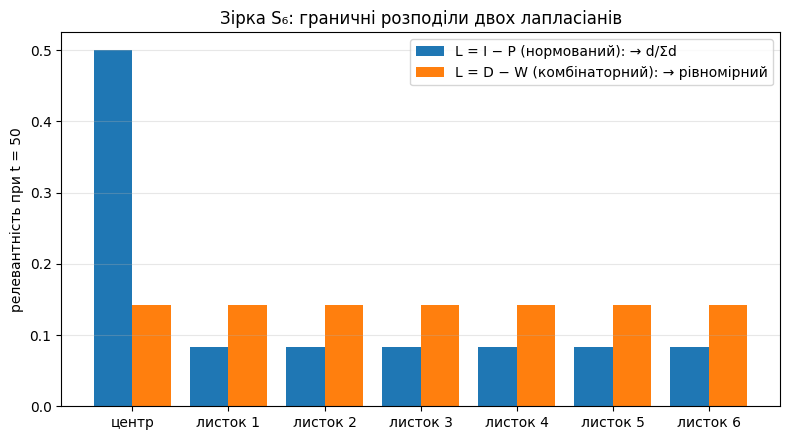

Нормований лапласіан: центр = 0.5000 (d/Σd = 0.5), листок = 0.0833 (1/12 = 0.0833)
Комбінаторний: центр = 0.1429, листок = 0.1429 (1/7 = 0.1429); сума = 1.000000000000


In [4]:
g = nx.star_graph(6)
Wd = nx.to_numpy_array(g)
Lc = np.diag(Wd.sum(axis=1)) - Wd
s = np.zeros(7); s[1] = 1.0
u_comb = s @ sla.expm(-50 * Lc)
u_rw = rank(g, 1, "heat", t=50).to_numpy()

x = np.arange(7)
plt.figure(figsize=(8, 4.5))
plt.bar(x - 0.2, u_rw, 0.4, label="L = I − P (нормований): → d/Σd")
plt.bar(x + 0.2, u_comb, 0.4, label="L = D − W (комбінаторний): → рівномірний")
plt.xticks(x, ["центр"] + [f"листок {i}" for i in range(1, 7)])
plt.ylabel("релевантність при t = 50"); plt.title("Зірка S₆: граничні розподіли двох лапласіанів")
plt.grid(alpha=0.3, axis="y"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "00_kontrast_laplasiany.png", dpi=200); plt.show()
print(f"Нормований лапласіан: центр = {u_rw[0]:.4f} (d/Σd = 0.5), листок = {u_rw[2]:.4f} (1/12 = {1/12:.4f})")
print(f"Комбінаторний: центр = {u_comb[0]:.4f}, листок = {u_comb[2]:.4f} (1/7 = {1/7:.4f}); сума = {u_comb.sum():.12f}")

## Завдання 3. Порівняння з аналітичними розв'язками

Звіряємо чисельні розв'язки з формулами (5)–(17):

- цикл: PPR (10) і теплове ядро (8);
- ланцюжок: складання циклу (11)–(12);
- зірка: (13)–(16);
- повний граф: (6)–(7).

На рисунках лінії — аналітичний розв'язок, маркери — чисельний.

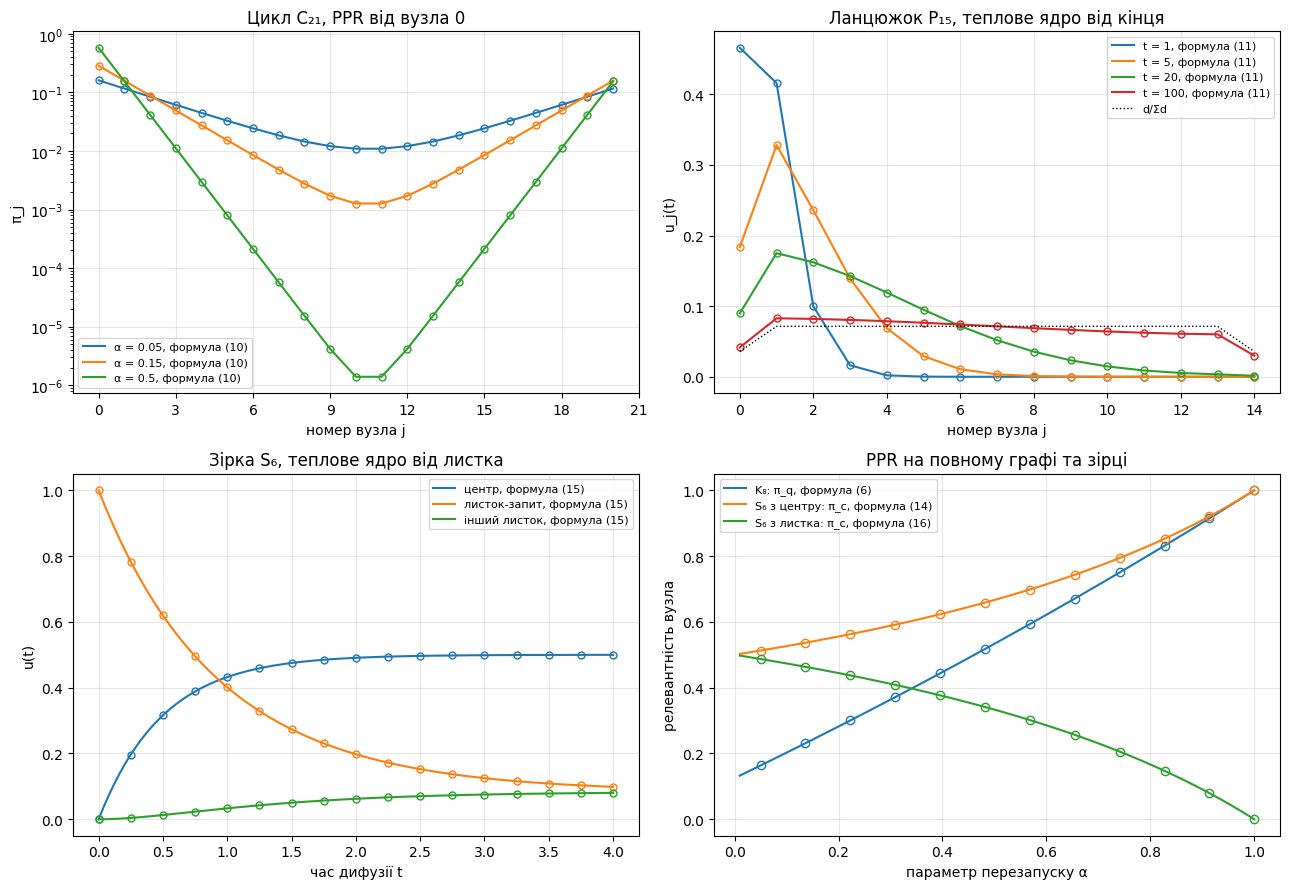

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))

# а) цикл, PPR — геометричне спадання
n = 21
ax = axs[0, 0]
for alpha in (0.05, 0.15, 0.5):
    x = rank(nx.cycle_graph(n), 0, "ppr", alpha=alpha).to_numpy()
    line, = ax.semilogy(range(n), A.cycle_ppr(n, alpha), lw=1.5, label=f"α = {alpha}, формула (10)")
    ax.semilogy(range(n), x, "o", ms=5, mfc="none", color=line.get_color())
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("Цикл C₂₁, PPR від вузла 0"); ax.set_xlabel("номер вузла j"); ax.set_ylabel("π_j")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

# б) ланцюжок, теплове ядро від кінця
n = 15
ax = axs[0, 1]
for t in (1.0, 5.0, 20.0, 100.0):
    x = rank(nx.path_graph(n), 0, "heat", t=t).to_numpy()
    line, = ax.plot(range(n), A.path_heat(n, t), lw=1.5, label=f"t = {t:g}, формула (11)")
    ax.plot(range(n), x, "o", ms=5, mfc="none", color=line.get_color())
ax.plot(range(n), stationary(nx.path_graph(n)), "k:", lw=1, label="d/Σd")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("Ланцюжок P₁₅, теплове ядро від кінця"); ax.set_xlabel("номер вузла j"); ax.set_ylabel("u_j(t)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

# в) зірка, теплове ядро від листка
m = 6
ax = axs[1, 0]
tt = np.linspace(0, 4, 200); tm = np.linspace(0, 4, 17)
Ua = np.array([A.star_heat(m, t, leaf=1) for t in tt])
Un = np.array([rank(nx.star_graph(m), 1, "heat", t=t).to_numpy() for t in tm])
for j, lab in ((0, "центр"), (1, "листок-запит"), (2, "інший листок")):
    line, = ax.plot(tt, Ua[:, j], lw=1.5, label=f"{lab}, формула (15)")
    ax.plot(tm, Un[:, j], "o", ms=5, mfc="none", color=line.get_color())
ax.set_title("Зірка S₆, теплове ядро від листка"); ax.set_xlabel("час дифузії t"); ax.set_ylabel("u(t)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

# г) повний граф і зірка, PPR як функція α
ax = axs[1, 1]
al = np.linspace(0.01, 1, 200); am = np.linspace(0.05, 1, 12)
ax.plot(al, [A.complete_ppr(8, a)[0] for a in al], lw=1.5, label="K₈: π_q, формула (6)")
ax.plot(am, [rank(nx.complete_graph(8), 0, "ppr", alpha=a)[0] for a in am], "o", mfc="none", color="C0")
ax.plot(al, [A.star_ppr(6, a)[0] for a in al], lw=1.5, label="S₆ з центру: π_c, формула (14)")
ax.plot(am, [rank(nx.star_graph(6), 0, "ppr", alpha=a)[0] for a in am], "o", mfc="none", color="C1")
ax.plot(al, [A.star_ppr(6, a, leaf=1)[0] for a in al], lw=1.5, label="S₆ з листка: π_c, формула (16)")
ax.plot(am, [rank(nx.star_graph(6), 1, "ppr", alpha=a)[0] for a in am], "o", mfc="none", color="C2")
ax.set_title("PPR на повному графі та зірці"); ax.set_xlabel("параметр перезапуску α"); ax.set_ylabel("релевантність вузла")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

plt.tight_layout(); plt.savefig(FIG / "00_analitychni_rozvyazky.png", dpi=200); plt.show()

Таблиця максимальних похибок на сітках параметрів. Для PPR α ∈ {0.01, 0.05, 0.15, 0.5, 0.9, 1}, для теплового ядра t ∈ {0, 0.1, 1, 5, 20, 100}. Розміри графів: n = 5, 12, 31; вузол запиту — перший вузол, для зірки ще й листок.

In [6]:
ALPHAS = [0.01, 0.05, 0.15, 0.5, 0.9, 1.0]
TIMES = [0.0, 0.1, 1.0, 5.0, 20.0, 100.0]
SIZES = [5, 12, 31]

def max_err(make_g, q, ref_ppr, ref_heat):
    rows = []
    for n in SIZES:
        g = make_g(n)
        e = max(np.abs(rank(g, q, "ppr", alpha=a).to_numpy() - ref_ppr(n, a)).max() for a in ALPHAS)
        rows.append(("PPR, лінійна система", n, e))
        for solver in ("expm_multiply", "series", "dense"):
            e = max(np.abs(rank(g, q, "heat", t=t, solver=solver).to_numpy() - ref_heat(n, t)).max()
                    for t in TIMES)
            rows.append((f"теплове ядро, {solver}", n, e))
    return rows

spec = {
    "повний граф": (nx.complete_graph, 0, A.complete_ppr, A.complete_heat),
    "цикл": (nx.cycle_graph, 0, A.cycle_ppr, A.cycle_heat),
    "ланцюжок (від кінця)": (nx.path_graph, 0, A.path_ppr, A.path_heat),
    "ланцюжок (від середини)": (nx.path_graph, 2, lambda n, a: A.path_ppr(n, a, q=2),
                                lambda n, t: A.path_heat(n, t, q=2)),
    "зірка (з центру)": (lambda n: nx.star_graph(n - 1), 0, lambda n, a: A.star_ppr(n - 1, a),
                         lambda n, t: A.star_heat(n - 1, t)),
    "зірка (з листка)": (lambda n: nx.star_graph(n - 1), 1, lambda n, a: A.star_ppr(n - 1, a, leaf=1),
                         lambda n, t: A.star_heat(n - 1, t, leaf=1)),
}
rows = []
for gname, (make_g, q, rp, rh) in spec.items():
    for method, n, e in max_err(make_g, q, rp, rh):
        rows.append(dict(граф=gname, спосіб=method, n=n, макс_похибка=e))
tab_an = pd.DataFrame(rows)
tab_an_pivot = tab_an.pivot_table(index=["граф", "спосіб"], columns="n", values="макс_похибка")
tab_an.to_csv(RES / "00_analitychni_pokhybky.csv", index=False)
display(tab_an_pivot)
print(f"Найбільша похибка відносно аналітичних розв'язків: {tab_an['макс_похибка'].max():.2e}")

n                                                         5        12       31
граф                    спосіб                                                
зірка (з листка)        PPR, лінійна система        9.99e-16 1.61e-15 1.22e-15
                        теплове ядро, dense         8.88e-16 1.09e-14 4.55e-14
                        теплове ядро, expm_multiply 6.05e-15 3.22e-15 3.55e-15
                        теплове ядро, series        2.22e-16 1.67e-15 7.77e-16
зірка (з центру)        PPR, лінійна система        8.88e-16 1.44e-15 1.22e-15
                        теплове ядро, dense         8.33e-16 1.14e-14 4.53e-14
                        теплове ядро, expm_multiply 6.16e-15 3.55e-15 3.55e-15
                        теплове ядро, series        1.11e-16 2.22e-16 3.89e-16
ланцюжок (від кінця)    PPR, лінійна система        3.33e-16 2.22e-16 2.22e-16
                        теплове ядро, dense         5.55e-16 1.73e-15 2.19e-15
                        теплове ядро, expm_multiply 3.39e-15 1.73e-15 2.19e-15
                        теплове ядро, series        4.02e-16 1.73e-15 2.19e-15
ланцюжок (від середини) PPR, лінійна система        2.78e-16 3.33e-16 3.33e-16
                        теплове ядро, dense         6.66e-16 2.15e-15 2.29e-15
                        теплове ядро, expm_multiply 3.08e-15 2.15e-15 2.29e-15
                        теплове ядро, series        3.52e-16 2.15e-15 2.29e-15
повний граф             PPR, лінійна система        2.22e-16 1.08e-15 1.33e-15
                        теплове ядро, dense         1.47e-15 7.36e-16 3.83e-15
                        теплове ядро, expm_multiply 1.92e-15 1.11e-16 1.94e-16
                        теплове ядро, series        6.11e-16 1.11e-16 2.08e-16
цикл                    PPR, лінійна система        8.60e-16 1.25e-16 2.22e-16
                        теплове ядро, dense         9.44e-16 8.33e-16 2.03e-15
                        теплове ядро, expm_multiply 1.75e-15 1.11e-15 2.03e-15
                        теплове ядро, series        7.49e-16 4.53e-16 2.03e-15

Найбільша похибка відносно аналітичних розв'язків: 4.55e-14


## Завдання 4. Збіг способів розрахунку

Усередині кожної моделі порівнюємо способи розрахунку з щільним еталоном:

- **PPR:** ітерація (tol = 10⁻¹³) і розріджена лінійна система (`spsolve`) проти щільної оберненої матриці;
- **теплове ядро:** обрізаний ряд і `expm_multiply` проти щільної `scipy.linalg.expm`.

Порівнюємо на трьох випадкових графах (n = 300). На орієнтованому графі перевіряємо обидві стратегії для висячих вузлів.

In [7]:
rows = []
for name, g in GRAPHS.items():
    for dangling in (("restart", "self_loop") if g.is_directed() else ("restart",)):
        lab = name + (f", {dangling}" if g.is_directed() else "")
        for alpha in (0.01, 0.15, 0.5, 0.9):
            ref = rank(g, 0, "ppr", alpha=alpha, solver="dense", dangling=dangling).to_numpy()
            it = rank(g, 0, "ppr", alpha=alpha, solver="iterative", dangling=dangling, tol=1e-13).to_numpy()
            li = rank(g, 0, "ppr", alpha=alpha, solver="linear", dangling=dangling).to_numpy()
            rows.append(dict(граф=lab, модель="PPR", параметр=f"α = {alpha}",
                             спосіб_1="ітерація", похибка_1=np.abs(it - ref).sum(),
                             спосіб_2="лінійна система", похибка_2=np.abs(li - ref).sum()))
        for t in (0.5, 3.0, 12.0, 50.0):
            ref = rank(g, 0, "heat", t=t, solver="dense", dangling=dangling).to_numpy()
            se = rank(g, 0, "heat", t=t, solver="series", dangling=dangling).to_numpy()
            em = rank(g, 0, "heat", t=t, solver="expm_multiply", dangling=dangling).to_numpy()
            rows.append(dict(граф=lab, модель="теплове ядро", параметр=f"t = {t}",
                             спосіб_1="обрізаний ряд", похибка_1=np.abs(se - ref).sum(),
                             спосіб_2="expm_multiply", похибка_2=np.abs(em - ref).sum()))
tab_agree = pd.DataFrame(rows)
tab_agree.to_csv(RES / "00_zbih_sposobiv.csv", index=False)
display(tab_agree)
for model in ("PPR", "теплове ядро"):
    sub = tab_agree[tab_agree["модель"] == model]
    print(f"{model}: макс. ‖x − x_щільний‖₁ = {sub[['похибка_1', 'похибка_2']].max().max():.2e}")

,граф,модель,параметр,спосіб_1,похибка_1,спосіб_2,похибка_2
0,ER (n=300),PPR,α = 0.01,ітерація,2.21e-15,лінійна система,9.74e-16
1,ER (n=300),PPR,α = 0.15,ітерація,6.41e-15,лінійна система,5.37e-16
2,ER (n=300),PPR,α = 0.5,ітерація,1.52e-14,лінійна система,1.78e-16
3,ER (n=300),PPR,α = 0.9,ітерація,4.76e-15,лінійна система,2.59e-16
4,ER (n=300),теплове ядро,t = 0.5,обрізаний ряд,1.39e-16,expm_multiply,3.07e-16
5,ER (n=300),теплове ядро,t = 3.0,обрізаний ряд,6.12e-16,expm_multiply,6.04e-16
6,ER (n=300),теплове ядро,t = 12.0,обрізаний ряд,1.01e-15,expm_multiply,5.16e-16
7,ER (n=300),теплове ядро,t = 50.0,обрізаний ряд,1.90e-15,expm_multiply,5.88e-15
8,WS зважений (n=300),PPR,α = 0.01,ітерація,2.16e-14,лінійна система,9.28e-16
9,WS зважений (n=300),PPR,α = 0.15,ітерація,7.93e-14,лінійна система,2.45e-16


PPR: макс. ‖x − x_щільний‖₁ = 7.93e-14
теплове ядро: макс. ‖x − x_щільний‖₁ = 6.29e-15


## Завдання 5. Похибка ітерацій PPR

За оцінкою (18): ‖π_k − π*‖₁ ≤ (1 − α)^k·‖s − π*‖₁. На графіку суцільна лінія — фактична похибка, пунктир — ця оцінка.

Асимптотично похибка спадає як ((1 − α)·|λ₂|)^k. Тому чим менше |λ₂| (краще перемішування графа), тим швидше ітерації випереджають гарантовану оцінку. Нижче оцінюємо фактичну швидкість за нахилом ln‖π_k − π*‖₁ на останній частині кривої. Задаємо tol = 10⁻¹⁴: для малих α це нижче досяжної точності (через множник (1 − α)/α у (19)), і тоді ітерації зупиняються за застоєм нев'язки. Стовпчик «зупинка» показує, який критерій спрацював.

ER (n=300): |λ₂| = 0.7206


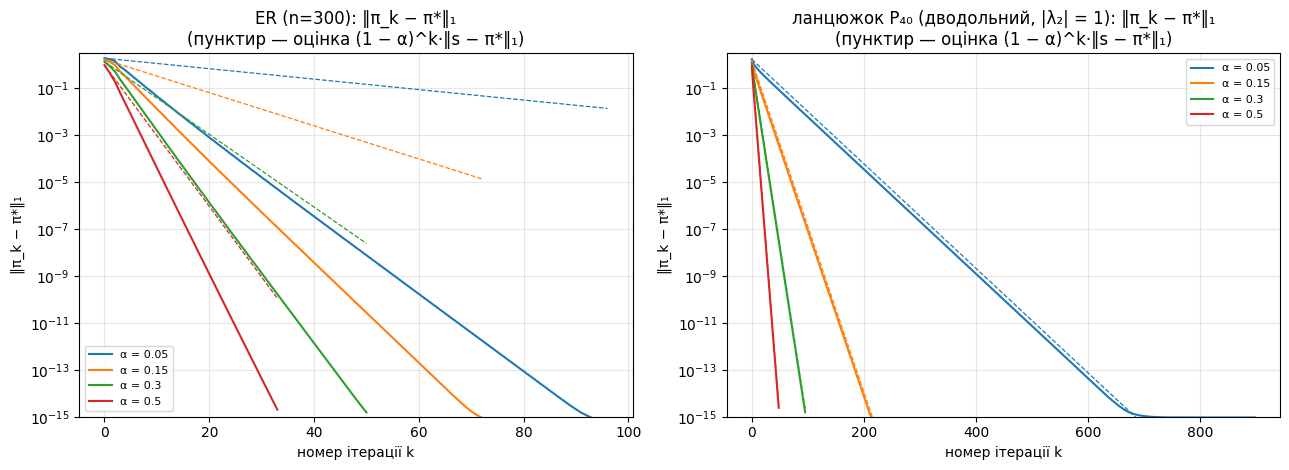

,граф,α,ітерацій,зупинка,ε_останнє,фактична_швидкість,оцінка_1_мінус_α,асимптотика_1_мінус_α_на_λ2,оцінка_виконана
0,ER (n=300),0.05,96,критерій (19),7.453e-16,0.6832,0.95,0.6846,True
1,ланцюжок P₄₀,0.05,897,застій (округлення),9.316e-16,0.95,0.95,0.95,True
2,ER (n=300),0.15,72,критерій (19),9.104e-16,0.6102,0.85,0.6125,True
3,ланцюжок P₄₀,0.15,215,критерій (19),8.084e-16,0.85,0.85,0.85,True
4,ER (n=300),0.3,50,критерій (19),1.538e-15,0.5006,0.7,0.5044,True
5,ланцюжок P₄₀,0.3,95,критерій (19),1.552e-15,0.7,0.7,0.7,True
6,ER (n=300),0.5,33,критерій (19),2.008e-15,0.3548,0.5,0.3603,True
7,ланцюжок P₄₀,0.5,48,критерій (19),2.407e-15,0.5,0.5,0.5,True


In [8]:
lam2_er = second_eig(g_er)
print(f"ER (n=300): |λ₂| = {lam2_er:.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
rows = []
for alpha in (0.05, 0.15, 0.3, 0.5):
    for ax, (name, g) in zip((a1, a2), (("ER (n=300)", g_er), ("ланцюжок P₄₀", nx.path_graph(40)))):
        _, info = rank(g, 0, "ppr", alpha=alpha, solver="iterative", tol=1e-14,
                       track_error=True, return_info=True)
        err = info["errors"]; k = np.arange(err.size)
        line, = ax.semilogy(k, err, lw=1.5, label=f"α = {alpha}")
        ax.semilogy(k, (1 - alpha) ** k * err[0], "--", lw=0.9, color=line.get_color())
        # фактична швидкість — нахил на ділянці, де похибка між 1e-4 і 1e-12
        mask = (err < 1e-4) & (err > 1e-12)
        rate = np.exp(np.polyfit(k[mask], np.log(err[mask]), 1)[0]) if mask.sum() > 3 else np.nan
        lam2 = lam2_er if g is g_er else second_eig(g)
        rows.append(dict(граф=name, α=alpha, ітерацій=info["n_iter"], зупинка=("критерій (19)" if info["converged"] else "застій (округлення)"), ε_останнє=err[-1],
                         фактична_швидкість=rate, оцінка_1_мінус_α=1 - alpha,
                         асимптотика_1_мінус_α_на_λ2=(1 - alpha) * lam2,
                         оцінка_виконана=bool(np.all(err <= (1 - alpha) ** k * err[0] + 1e-14))))
for ax, name in ((a1, "ER (n=300)"), (a2, "ланцюжок P₄₀ (дводольний, |λ₂| = 1)")):
    ax.set_ylim(1e-15, 3)
    ax.set_title(f"{name}: ‖π_k − π*‖₁\n(пунктир — оцінка (1 − α)^k·‖s − π*‖₁)")
    ax.set_xlabel("номер ітерації k"); ax.set_ylabel("‖π_k − π*‖₁")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "00_pokhybka_iteratsiy.png", dpi=200); plt.show()

tab_it = pd.DataFrame(rows)
tab_it.to_csv(RES / "00_pokhybka_iteratsiy.csv", index=False)
pd.set_option("display.float_format", "{:.4g}".format)
display(tab_it)

## Завдання 6. Граничні випадки параметрів

- α = 1 ⇒ π* = s;
- t = 0 ⇒ u = s;
- α → 0 ⇒ π* → d/Σd, причому і на дводольному графі, бо PPR при малому α — це середнє за Чезаро;
- t → ∞ ⇒ u → d/Σd.

Залежність від α для PPR перевіряємо на ланцюжку P₇ (дводольний).

α = 1: ‖π* − s‖₁ = 0.00e+00
t = 0: ‖u − s‖₁ = 0.00e+00


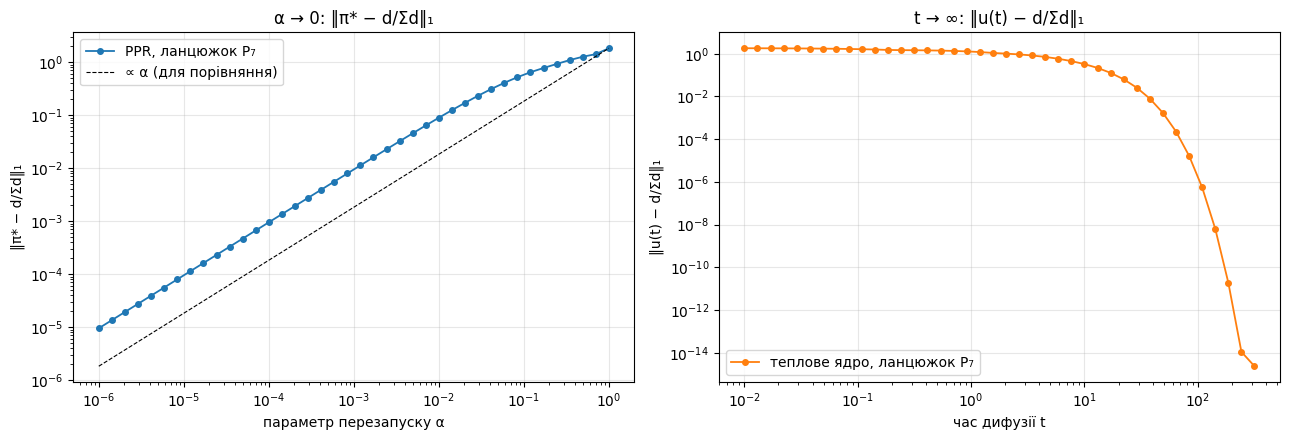

Нахил log‖π* − d/Σd‖₁ від log α при малих α: 1.000
α = 1e-6: ‖π* − d/Σd‖₁ = 9.53e-06; t = 316: ‖u − d/Σd‖₁ = 2.33e-15


In [9]:
g = nx.path_graph(7); pi_inf = stationary(g)
print(f"α = 1: ‖π* − s‖₁ = {np.abs(rank(g, 0, 'ppr', alpha=1.0).to_numpy() - np.eye(7)[0]).sum():.2e}")
print(f"t = 0: ‖u − s‖₁ = {np.abs(rank(g, 0, 'heat', t=0.0).to_numpy() - np.eye(7)[0]).sum():.2e}")

alphas = np.logspace(-6, 0, 40)
err_a = [np.abs(rank(g, 0, "ppr", alpha=a).to_numpy() - pi_inf).sum() for a in alphas]
ts = np.logspace(-2, 2.5, 40)
err_t = [np.abs(rank(g, 0, "heat", t=t).to_numpy() - pi_inf).sum() for t in ts]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.loglog(alphas, err_a, "o-", ms=4, lw=1.3, label="PPR, ланцюжок P₇")
a1.loglog(alphas, alphas * err_a[-1] / alphas[-1], "k--", lw=0.8, label="∝ α (для порівняння)")
a1.set_title("α → 0: ‖π* − d/Σd‖₁"); a1.set_xlabel("параметр перезапуску α"); a1.set_ylabel("‖π* − d/Σd‖₁")
a2.semilogx(ts, err_t, "o-", ms=4, lw=1.3, color="C1", label="теплове ядро, ланцюжок P₇")
a2.set_yscale("log")
a2.set_title("t → ∞: ‖u(t) − d/Σd‖₁"); a2.set_xlabel("час дифузії t"); a2.set_ylabel("‖u(t) − d/Σd‖₁")
for ax in (a1, a2):
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "00_hranychni_vypadky.png", dpi=200); plt.show()
slope = np.polyfit(np.log(alphas[:15]), np.log(err_a[:15]), 1)[0]
print(f"Нахил log‖π* − d/Σd‖₁ від log α при малих α: {slope:.3f}")
print(f"α = 1e-6: ‖π* − d/Σd‖₁ = {err_a[0]:.2e}; t = {ts[-1]:.0f}: ‖u − d/Σd‖₁ = {err_t[-1]:.2e}")

## Висновки

1. **Збереження суми і невід'ємність.** Усі способи розрахунку обох моделей зберігають суму релевантності з точністю до округлення: найбільше |Σπ − 1| = 1.77·10⁻¹⁴, від'ємних компонент немає (мінімум 0). Це виконується і на зваженому графі, і на орієнтованому з 16 висячими вузлами за обох стратегій.
2. **Аналітичні розв'язки і збіг способів.** Чисельні розв'язки збігаються з формулами (5)–(17) для повного графа, циклу, ланцюжка і зірки з максимальною похибкою 4.55·10⁻¹⁴. Усередині кожної моделі способи збігаються з щільним еталоном: для PPR ‖·‖₁ ≤ 7.93·10⁻¹⁴, для теплового ядра ≤ 6.29·10⁻¹⁵.
3. **Блукання без перезапуску.** На недводольних графах блукання збігається до d/Σd зі швидкістю |λ₂|^k, як і передбачає теорія: для C₁₁ |λ₂| = 0.959, і через 300 кроків похибка ще 5.2·10⁻⁶; для ER |λ₂| = 0.721, і похибка доходить до рівня округлення. На парному циклі C₁₀ похибка після 300 кроків дорівнює 1.0 (коливання). Ліниве блукання знижує її до 1.1·10⁻¹³, а теплове ядро збігається і на дводольних графах. Для контрасту: з комбінаторним лапласіаном D − W дифузія на зірці S₆ дає рівномірний розподіл (0.1429 у кожному вузлі), а не 0.5 у центрі.
4. **Похибка ітерацій PPR.** Оцінка ‖π_k − π*‖₁ ≤ (1 − α)^k·‖s − π*‖₁ виконана на кожному кроці для всіх α. Фактична швидкість на ER близька до (1 − α)·|λ₂| (для α = 0.15: 0.610 проти 0.6125). На дводольному ланцюжку, де |λ₂| = 1, вона точно дорівнює 1 − α, тобто оцінка точна. При α = 0.05 точність tol = 10⁻¹⁴ недосяжна через множник (1 − α)/α у критерії (19), і ітерації зупиняються за застоєм нев'язки на рівні ~10⁻¹⁵.
5. **Граничні випадки.** При α = 1 і t = 0 отримуємо точно s. При α → 0 відхилення PPR від d/Σd спадає пропорційно α (нахил 1.000 у логарифмічних осях) навіть на дводольному ланцюжку. Отже, модель і її реалізація узгоджуються з теорією в усіх перевірках.